<a href="https://colab.research.google.com/github/JuCaRiCo/202602-AnaliticaDescriptivaPredictiva/blob/main/ArbolDeDecisionSemana12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Árboles de Regresión
### Maestría en Inteligencia Artificial y Analítica de Datos
**Módulo:** Analítica Predictiva · Sesión 24  
**Dataset:** California Housing
**Alumno**: Juan Carlos Rivera Cordova
**Matricula**: 271760

**1. Carga y exploración de datos**
- Cargar el dataset en un DataFrame
- Identificar la variable objetivo (MedHouseVal)
- Analizar la estructura del dataset (info, describe)
- Visualizar la distribución de la variable objetivo

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_california_housing

____PRIMERAS FILAS DEL DATASET____
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  MedHouseVal  
0    -122.23        4.526  
1    -122.22        3.585  
2    -122.24        3.521  
3    -122.25        3.413  
4    -122.25        3.422  

____INFORMACIÓN GENERAL (df.info())____
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640

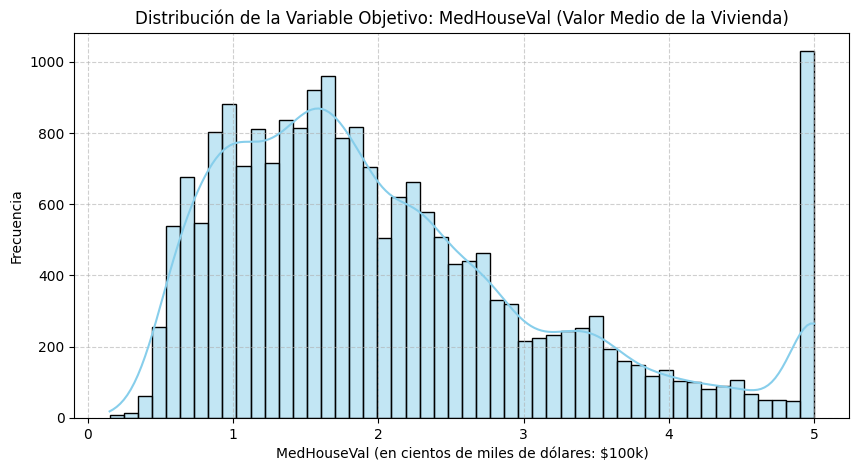

In [15]:
# 1. CARGA Y EXPLORACIÓN DE DATOS

# 1.1 Cargar el dataset desde scikit-learn
housing = fetch_california_housing(as_frame=True)

# Convertir a DataFrame de pandas
df = housing.frame

# 1.2 Identificar la variable objetivo (MedHouseVal) y las características (features)
print("____PRIMERAS FILAS DEL DATASET____")
print(df.head())

# 1.3 Analizar la estructura del dataset
print("\n____INFORMACIÓN GENERAL (df.info())____")
df.info()

print("\n____ESTADÍSTICAS DESCRIPTIVAS (df.describe())____")
print(df.describe().T)

# Verificar si existen valores nulos
print("\n____VALORES FALTANTES POR COLUMNA____")
print(df.isnull().sum())

# 1.4 Visualizar la distribución de la variable objetivo (MedHouseVal)
plt.figure(figsize=(10, 5))
sns.histplot(df['MedHouseVal'], kde=True, color='skyblue', bins=50)
plt.title('Distribución de la Variable Objetivo: MedHouseVal (Valor Medio de la Vivienda)')
plt.xlabel('MedHouseVal (en cientos de miles de dólares: $100k)')
plt.ylabel('Frecuencia')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

**2. Preparación de datos**

- Definir:
  - X: variabls predictoras
  - y: variable objetivo
- Dividir los datos en entrenamiento (80%) y prueba (20%)

In [16]:
# 2. PREPARACIÓN DE DATOS

from sklearn.model_selection import train_test_split

# 2.1 Definir variables predictoras (X) y variable objetivo (y)
X = df.drop(columns=['MedHouseVal'])
y = df['MedHouseVal']

# 2.2 Dividir los datos en conjunto de entrenamiento (80%) y prueba (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Confirmar dimensiones de los conjuntos creados
print("____DIMENSIONES DE LOS CONJUNTOS DE DATOS____")
print(f"X_train (Entrenamiento): {X_train.shape}")
print(f"X_test  (Prueba):        {X_test.shape}")
print(f"y_train (Entrenamiento): {y_train.shape}")
print(f"y_test  (Prueba):        {y_test.shape}")

____DIMENSIONES DE LOS CONJUNTOS DE DATOS____
X_train (Entrenamiento): (16512, 8)
X_test  (Prueba):        (4128, 8)
y_train (Entrenamiento): (16512,)
y_test  (Prueba):        (4128,)


**3. Modelo base**
- Entrenar un árbol de decisión sin restricciones (max_depth=None)
- Evaluar el modelo usando:
  - RMSE
  - R²
- Comparar desempeño en entrenamiento y prueba
- Determinar si existe sobreajuste

In [17]:
# 3. MODELO BASE (Sín restricciones)

from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, r2_score

# 3.1 Instanciar y entrenar el árbol base sin restricciones de profundidad
tree_base = DecisionTreeRegressor(random_state=42)
tree_base.fit(X_train, y_train)

# Obtener métricas estructurales del árbol resultante
profundidad_base = tree_base.get_depth()
hojas_base = tree_base.get_n_leaves()

# 3.2 Realizar predicciones en entrenamiento y prueba
y_train_pred = tree_base.predict(X_train)
y_test_pred = tree_base.predict(X_test)

# Calcular métricas RMSE y R²
rmse_train = np.sqrt(mean_squared_error(y_train, y_train_pred))
rmse_test = np.sqrt(mean_squared_error(y_test, y_test_pred))

r2_train = r2_score(y_train, y_train_pred)
r2_test = r2_score(y_test, y_test_pred)

# 3.3 Mostrar resultados comparativos
print("____ESTRUCTURA DEL ÁRBOL BASE____")
print(f"Profundidad máxima alcanzada: {profundidad_base}")
print(f"Número total de hojas:       {hojas_base}")

print("\n____DESEMPEÑO DEL MODELO BASE____")
print(f"Entrenamiento | RMSE: ${rmse_train*100000:.2f} ({rmse_train:.4f}) | R²: {r2_train:.4f}")
print(f"Prueba        | RMSE: ${rmse_test*100000:.2f} ({rmse_test:.4f}) | R²: {r2_test:.4f}")

____ESTRUCTURA DEL ÁRBOL BASE____
Profundidad máxima alcanzada: 34
Número total de hojas:       15854

____DESEMPEÑO DEL MODELO BASE____
Entrenamiento | RMSE: $0.00 (0.0000) | R²: 1.0000
Prueba        | RMSE: $70372.95 (0.7037) | R²: 0.6221


**4. Análisis Bias–Variance**
- Entrenar múltiples modelos variando el parámetro max_depth de 1 a 21.
- Graficar el error (RMSE) en entrenamiento y prueba
- Identificar el punto donde el modelo generaliza mejor

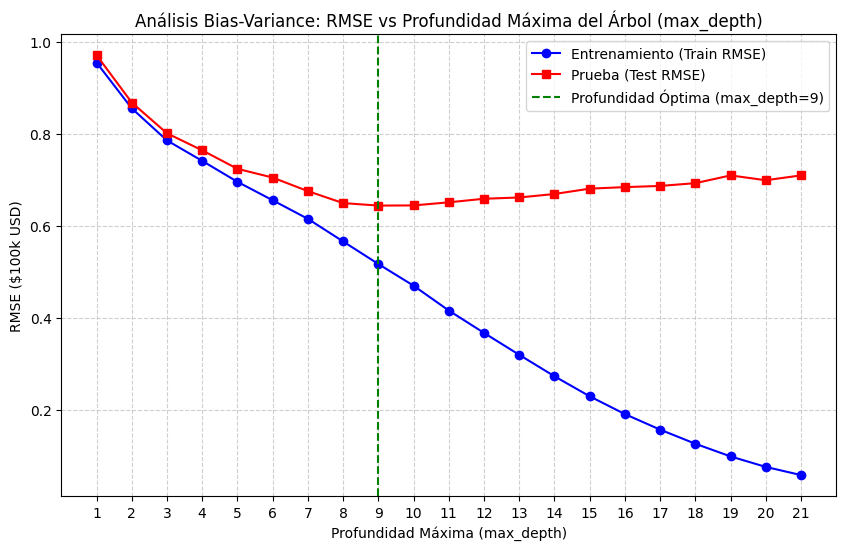

____ANÁLISIS DEL OPTIMO____
La profundidad óptima donde el modelo generaliza mejor es: max_depth = 9
RMSE de Prueba en max_depth=9: $64425.78 (0.6443)
RMSE de Entrenamiento en max_depth=9: $51716.07 (0.5172)


In [18]:
# 4. ANÁLISIS BIAS–VARIANCE (EFECTO DE MAX_DEPTH)

# 4.1 Entrenar modelos variando max_depth de 1 a 21
depths = range(1, 22)
train_rmse_list = []
test_rmse_list = []

for depth in depths:
    # Instanciar árbol con la profundidad actual
    tree_depth = DecisionTreeRegressor(max_depth=depth, random_state=42)
    tree_depth.fit(X_train, y_train)

    # Predecir
    y_train_pred = tree_depth.predict(X_train)
    y_test_pred = tree_depth.predict(X_test)

    # Calcular y guardar RMSE
    rmse_tr = np.sqrt(mean_squared_error(y_train, y_train_pred))
    rmse_te = np.sqrt(mean_squared_error(y_test, y_test_pred))

    train_rmse_list.append(rmse_tr)
    test_rmse_list.append(rmse_te)

# 4.2 Graficar el error (RMSE) en entrenamiento y prueba
plt.figure(figsize=(10, 6))
plt.plot(depths, train_rmse_list, marker='o', color='blue', label='Entrenamiento (Train RMSE)')
plt.plot(depths, test_rmse_list, marker='s', color='red', label='Prueba (Test RMSE)')

# Identificar el punto de menor RMSE en el conjunto de prueba
best_depth_idx = np.argmin(test_rmse_list)
best_depth = depths[best_depth_idx]
best_test_rmse = test_rmse_list[best_depth_idx]

# Resaltar la profundidad óptima en la gráfica
plt.axvline(x=best_depth, color='green', linestyle='--', label=f'Profundidad Óptima (max_depth={best_depth})')

plt.title('Análisis Bias-Variance: RMSE vs Profundidad Máxima del Árbol (max_depth)')
plt.xlabel('Profundidad Máxima (max_depth)')
plt.ylabel('RMSE ($100k USD)')
plt.xticks(depths)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# 4.3 Mostrar resultados analíticos
print("____ANÁLISIS DEL OPTIMO____")
print(f"La profundidad óptima donde el modelo generaliza mejor es: max_depth = {best_depth}")
print(f"RMSE de Prueba en max_depth={best_depth}: ${best_test_rmse*100000:.2f} ({best_test_rmse:.4f})")
print(f"RMSE de Entrenamiento en max_depth={best_depth}: ${train_rmse_list[best_depth_idx]*100000:.2f} ({train_rmse_list[best_depth_idx]:.4f})")


**5. Poda del árbol**
- Aplicar cost-complexity pruning (ccp_alpha)
- Evaluar distintos valores de ccp_alpha con ccp_alphas = ccp_alphas[::5]
- Analizar su efecto en el error del modelo

In [28]:
from joblib import Parallel, delayed

# 5.1 Obtener la ruta de complejidad ccp_alphas a partir del árbol base
path = tree_base.cost_complexity_pruning_path(X_train, y_train)
ccp_alphas = path.ccp_alphas

# 5.2 Filtrar los valores de ccp_alpha según la instrucción (paso de 5 en 5)
ccp_alphas_sub = ccp_alphas[::5][:-1]  # Excluimos el último alpha extremo

# Función auxiliar para entrenar y evaluar cada alpha de manera independiente
def eval_alpha(alpha):
    clf = DecisionTreeRegressor(random_state=42, ccp_alpha=alpha)
    clf.fit(X_train, y_train)
    tr_rmse = np.sqrt(mean_squared_error(y_train, clf.predict(X_train)))
    te_rmse = np.sqrt(mean_squared_error(y_test, clf.predict(X_test)))
    return clf, tr_rmse, te_rmse

# 5.3 Ejecución en paralelo utilizando todos los núcleos del procesador (n_jobs=-1)
print(f"Evaluando {len(ccp_alphas_sub)} valores de ccp_alpha en paralelo...")
results = Parallel(n_jobs=-1)(delayed(eval_alpha)(alpha) for alpha in ccp_alphas_sub)

Evaluando 2966 valores de ccp_alpha en paralelo...


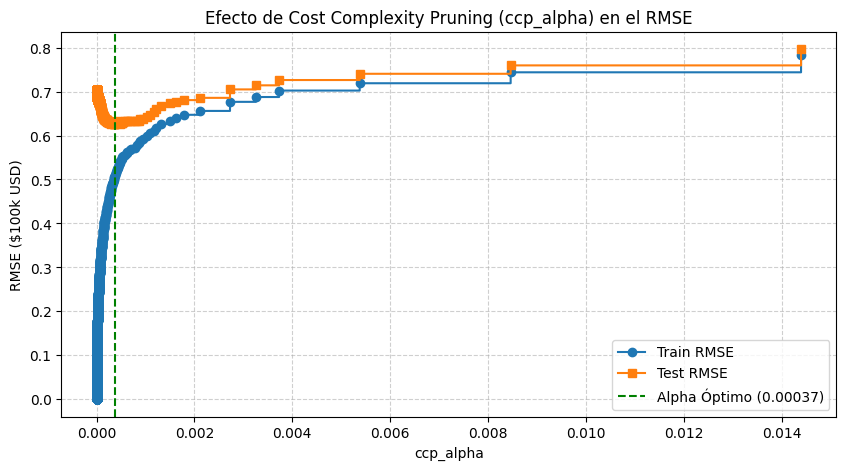

--- ANÁLISIS DEL EFECTO DE LA PODA ---
Alpha óptimo seleccionado:               0.000369
Profundidad del árbol podado:           16
Número de hojas del árbol podado:       271
RMSE de Prueba (Árbol Podado):          $62637.65 (0.6264)
R² de Prueba (Árbol Podado):            0.7006


In [29]:
# Desempaquetar los resultados en listas
clfs, train_rmse_ccp, test_rmse_ccp = zip(*results)
clfs = list(clfs)
train_rmse_ccp = list(train_rmse_ccp)
test_rmse_ccp = list(test_rmse_ccp)

# Identificar el alpha óptimo que minimiza el RMSE en el conjunto de prueba
best_idx = np.argmin(test_rmse_ccp)
best_alpha = ccp_alphas_sub[best_idx]
best_tree = clfs[best_idx]

# 5.4 Graficar el efecto de ccp_alpha en el RMSE del modelo
plt.figure(figsize=(10, 5))
plt.plot(ccp_alphas_sub, train_rmse_ccp, marker='o', label='Train RMSE', drawstyle="steps-post")
plt.plot(ccp_alphas_sub, test_rmse_ccp, marker='s', label='Test RMSE', drawstyle="steps-post")
plt.axvline(x=best_alpha, color='green', linestyle='--', label=f'Alpha Óptimo ({best_alpha:.5f})')

plt.title('Efecto de Cost Complexity Pruning (ccp_alpha) en el RMSE')
plt.xlabel('ccp_alpha')
plt.ylabel('RMSE ($100k USD)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# 5.5 Resumen numérico y análisis del árbol podado
print("--- ANÁLISIS DEL EFECTO DE LA PODA ---")
print(f"Alpha óptimo seleccionado:               {best_alpha:.6f}")
print(f"Profundidad del árbol podado:           {best_tree.get_depth()}")
print(f"Número de hojas del árbol podado:       {best_tree.get_n_leaves()}")
print(f"RMSE de Prueba (Árbol Podado):          ${test_rmse_ccp[best_idx]*100000:.2f} ({test_rmse_ccp[best_idx]:.4f})")
print(f"R² de Prueba (Árbol Podado):            {r2_score(y_test, best_tree.predict(X_test)):.4f}")

**Análisis del Efecto de la Poda:**

La poda sirve para eliminar las divisiones innecesarias del arbol que solo captura ruido. Sin pode, el modelo memoriza los datos de entrenamiento y pierde capacidad de predecir en datos nuevos. Al aplicar el ccp_alpha optimo, simplificamos el arbol para conservar unicamente las reglas con verdadero poder predictivo, logrando asi el error mas bajo en el conjunto de la prueba.

In [30]:
# Mostrar la importancia de cada variable en el árbol podado óptimo
importancias = pd.Series(best_tree.feature_importances_, index=X.columns).sort_values(ascending=False)

print("--- IMPORTANCIA DE VARIABLES (feature_importances_) ---")
print(importancias)

--- IMPORTANCIA DE VARIABLES (feature_importances_) ---
MedInc        0.628749
AveOccup      0.128744
Latitude      0.076381
Longitude     0.063837
HouseAge      0.043460
AveRooms      0.037030
Population    0.012286
AveBedrms     0.009512
dtype: float64


**6. Interpretación de resultados**

Responder de manera justificada:
- ¿El modelo base presenta sobreajuste? Explique

  Sí, el modelo base presenta un sobreajuste severo (high overfitting). Al entrenar el árbol sin restricciones (max_depth=None), el modelo creció de forma desmedida alcanzando una profundidad de 34 niveles y 15,854 hojas. Esto hizo que memorizara completamente los datos de entrenamiento RMSE = 0.0000 y $R^2$ = 1.0000, al evaluarlo con el conjunto de prueba, el error se dispara a RMSE = 0.7037 (\$70,372.95 USD) y el $R^2$ cae a 0.6221. Esta diferencia tan amplia entre entrenamiento perfecto y una menor precisión en prueba es la prueba directa de sobreajuste.

- ¿Cómo afecta la profundidad del árbol al error?

   La profundidad determina el equilibrio entre el sesgo y varianza, a profundidades bajas generan subajustes (entre 1 y 4), el arbol es demasiado simple y muestra errores elevados. La profundidad optima (9), representa el punto de equilibrio donde el error de prueba alcanza su minimo de 0.6443

- ¿Qué efecto tiene la poda en el modelo?

  La poda por complejidad de costos (ccp_alpha) elimina de forma sistemática los nodos y ramas superfluas que solo aportan varianza. En cuanto a optimizacion, elimina el sobreajuste del árbol base al reducir el RMSE de prueba de \$0.7037 a \$0.6264. En cuanto a simplificacion, reduce drásticamente la estructura de \$15,854 a solo \$271 hojas.

- ¿Cuál configuración produce el mejor desempeño?

  La mejor configuración se obtiene mediante la poda por complejidad con un valor de ccp_alpha = 0.000369. Con esta estructura (16 de profundidad y 271 hojas), el modelo alcanza su mayor capacidad de generalización en datos no vistos

- ¿Qué variables son más relevantes según el modelo?

  - MedInc (Ingreso Medio del Bloque): Es la variable dominante con el mayor peso en las divisiones. El nivel de ingreso de la zona condiciona directamente el valor de las viviendas.

  - AveOccup (Promedio de Ocupantes): Es relevante para identificar patrones de densidad de población e impacto por zonas urbanas.

  - Latitude y Longitude (Coordenadas Geográficas): Tienen un peso alto ya que capturan la ubicación espacial (proximidad a las costas de California y a zonas metropolitanas cotizadas como Los Ángeles y San Francisco).